# Week 6 Project Guide
## Probabilistic Models & Bayesian Inference
### Statistical Machine Learning · Fusemachines AI Fellowship · Susan Ghimire

---

**How to use this notebook**
- Read **Your Role** first so every modelling choice stays tied to the business question.
- Work through **Parts 1–6** in order; later sections reuse outputs from earlier ones.
- Fill every `# YOUR CODE HERE` block, answer every **✍ Reflect** prompt, and make sure each **SELF-CHECK** passes.
- Run the notebook top-to-bottom before submitting so all plots, HDIs, and trace diagnostics are visible.

**Your role**
You are the Data Scientist responsible for explaining churn risk and inference reliability to the VP of Retention. The core task is not to produce a single number, but to replace point estimates with posterior distributions and credible intervals wherever uncertainty matters.

| Responsibility | What it means in practice |
|---|---|
| Replace point estimates | Parts 1–2: compute MLE, MAP, full posteriors, and 94% HDIs for churn rates by contract type. |
| Quantify sequential evidence | Part 2: implement `update_posterior()` and show when the posterior becomes reliable. |
| Model feature dependencies | Parts 3–4: fit a Multivariate Gaussian, Bayesian Network, and MRF to the same Telco features. |
| Forecast with honest uncertainty | Part 5: fit a GP to Mauna Loa CO₂ and define the model confidence boundary. |
| Validate a Bayesian posterior | Part 6: fit a Bayesian Logistic Regression with PyMC/NUTS, diagnose convergence, and save the trace. |

**Datasets**
- **Telco Customer Churn**: used in Parts 1, 2, 3, 4, and 6. No new EDA is required; focus on probabilistic modelling.
- **Mauna Loa CO₂**: used in Part 5 only. Load it with `statsmodels` in three lines, with no CSV download.

**Submission requirements**
- Submit the completed `.ipynb` with all outputs visible and all cells executed in order.
- Submit `telco_bayes_lr_v1.pkl`, saved with `pickle.dump()` from the fitted PyMC `InferenceData`.
- Submit a one-page reflection in PDF or Markdown that answers the final Bayesian-vs-frequentist prompt in your own words.

**Common mistakes to avoid**
- Do not skip feature scaling before NUTS in Part 6.
- Do not use flat priors for logistic regression coefficients.
- Do not report MAP or MLE as if they were the full Bayesian answer.
- Do not leave Reflect cells generic; they must cite numeric results.

> **Mindset:** A model that gives you a number without a distribution is giving you an incomplete answer. This week, every important number should come with uncertainty attached.

---


In [5]:
# Run this cell first — all imports and data loading happen here

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import beta as beta_dist, dirichlet

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF,
    ExpSineSquared,
    WhiteKernel,
    DotProduct
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = [12, 5]

import matplotlib.colors as _mcolors
from cycler import cycler as _cycler

plt.rcParams['axes.prop_cycle'] = _cycler(
    color=[
        _mcolors.to_hex(c)
        for c in plt.rcParams['axes.prop_cycle'].by_key()['color']
    ]
)

# Telco data (Local CSV)

df_raw = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = df_raw.copy()

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'].astype(str).str.strip(),
    errors='coerce'
)

df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

df = df.drop(columns=['customerID'])

df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

print(f"Telco loaded: {df.shape}")
print(f"Churn rate: {df['Churn'].mean():.3f}")

Telco loaded: (7043, 20)
Churn rate: 0.265


---
## Part 1: The Estimation Trinity — MLE, MAP, Full Bayes

**Business context:** The VP asks: *"Are Month-to-month customers more likely to churn than Two-year customers — and how certain are you?"* Three statistical frameworks give three different answers.

---

### Q1 — Extract the experimental groups

Extract Group A (Month-to-month), Group B (Two-year), and Group A_small (40 rows from A).


In [6]:
# Extract contract groups for Bayesian comparisons

# Safer filtering (handles possible formatting variations)
group_A = df[df['Contract'] == 'Month-to-month'].copy()
group_B = df[df['Contract'].isin(['Two year', 'Two-year'])].copy()

# Small sample for low-data scenario
group_A_small = group_A.sample(n=40, random_state=42).copy()

# Remove any possible missing churn values (safe practice)
group_A = group_A.dropna(subset=['Churn'])
group_B = group_B.dropna(subset=['Churn'])
group_A_small = group_A_small.dropna(subset=['Churn'])

# Summary statistics
k_A, n_A = group_A['Churn'].sum(), len(group_A)
k_B, n_B = group_B['Churn'].sum(), len(group_B)
k_As, n_As = group_A_small['Churn'].sum(), len(group_A_small)

# ── SELF-CHECK 
assert n_As == 40
assert n_A > 3000
assert n_B > 1000

print(f"Group A  (M2M):  n={n_A}, k={k_A}, rate={k_A/n_A:.4f}")
print(f"Group A_small:   n={n_As}, k={k_As}, rate={k_As/n_As:.4f}")
print(f"Group B  (2yr):   n={n_B}, k={k_B}, rate={k_B/n_B:.4f}")

print("Groups extracted correctly!")

Group A  (M2M):  n=3875, k=1655, rate=0.4271
Group A_small:   n=40, k=15, rate=0.3750
Group B  (2yr):   n=1695, k=48, rate=0.0283
Groups extracted correctly!


### Q2 — Compute MLE, MAP, and plot all three posteriors

Use a **Beta(2, 8) prior** (encodes belief that most segments churn < 30%).


In [7]:
alpha_prior, beta_prior = 2, 8   # Beta(2, 8) prior — do not change

groups = {
    'Group A (M2M, large)': (k_A, n_A),
    'Group A_small (n=40)': (k_As, n_As),
    'Group B (2yr, large)': (k_B, n_B),
}

print(f"{'Group':<30} {'MLE':>8} {'MAP':>8} {'|MAP-MLE|':>12}")
print("-" * 62)

for name, (k, n) in groups.items():

    # MLE
    mle = k / n

    # MAP (Beta posterior mode)
    map_est = (alpha_prior + k - 1) / (alpha_prior + beta_prior + n - 2)

    # Difference between prior-influenced and data-only estimate
    pull = abs(map_est - mle)

    print(f"{name:<30} {mle:>8.4f} {map_est:>8.4f} {pull:>12.4f}")

Group                               MLE      MAP    |MAP-MLE|
--------------------------------------------------------------
Group A (M2M, large)             0.4271   0.4265       0.0006
Group A_small (n=40)             0.3750   0.3333       0.0417
Group B (2yr, large)             0.0283   0.0288       0.0005


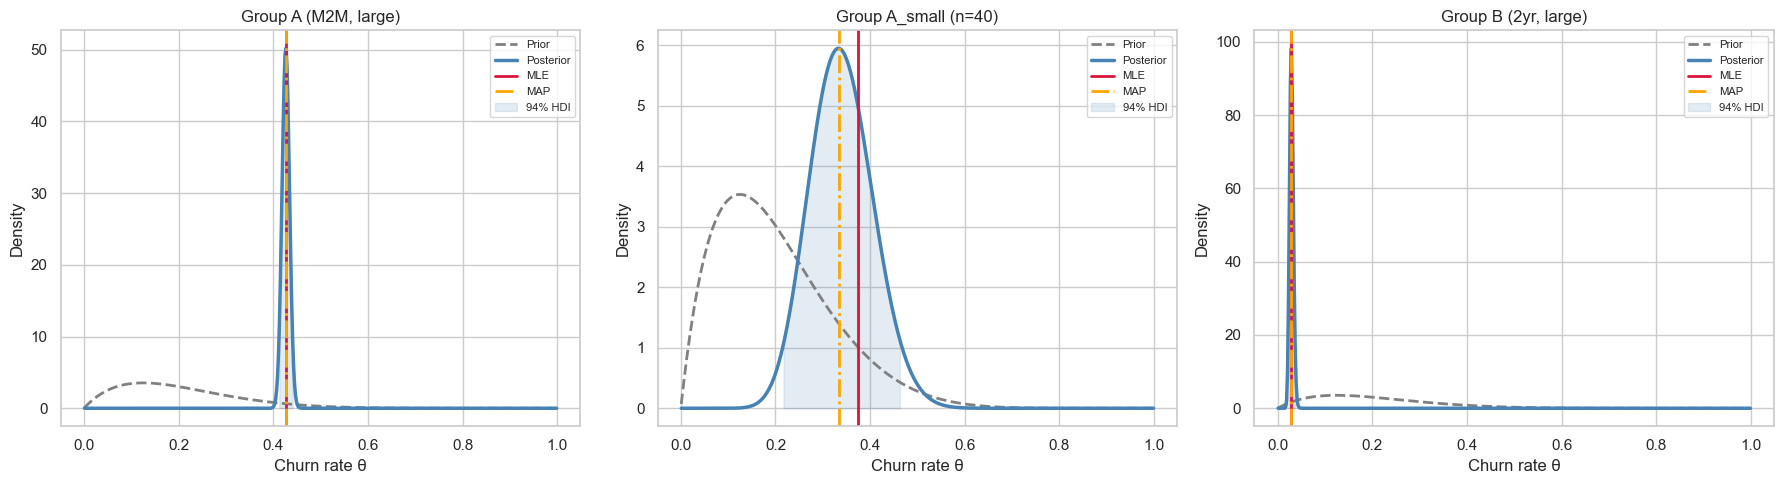

In [ ]:
import arviz as az  

theta_range = np.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (k, n)) in zip(axes, groups.items()):

    # Posterior parameters
    alpha_post = alpha_prior + k
    beta_post = beta_prior + (n - k)

    # Distributions
    prior_pdf = beta_dist.pdf(theta_range, alpha_prior, beta_prior)
    post_pdf = beta_dist.pdf(theta_range, alpha_post, beta_post)

    # Point estimates
    mle = k / n
    map_est = (alpha_prior + k - 1) / (alpha_prior + beta_prior + n - 2)

    # Stable HDI computation 
    samples = np.random.beta(alpha_post, beta_post, size=50_000)
    hdi = az.hdi(samples, prob=0.94)

    # Plot prior & posterior
    ax.plot(theta_range, prior_pdf, color='gray', lw=2, ls='--', label='Prior')
    ax.plot(theta_range, post_pdf, color='steelblue', lw=2.5, label='Posterior')

    # MLE & MAP lines
    ax.axvline(mle, color='crimson', lw=2, label='MLE')
    ax.axvline(map_est, color='orange', lw=2, ls='-.', label='MAP')

    # HDI shading
    ax.fill_between(
        theta_range,
        0,
        post_pdf,
        where=(theta_range >= hdi[0]) & (theta_range <= hdi[1]),
        color='steelblue',
        alpha=0.15,
        label='94% HDI'
    )

    ax.set_title(name)
    ax.set_xlabel('Churn rate θ')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Q3 — Answer the VP's question: P(θ_A > θ_B)

Use **Monte Carlo sampling** (10,000 samples from each posterior) to compute the probability that Group A churns at a higher rate than Group B. No p-value permitted.


In [10]:
MC_SAMPLES = 10_000
np.random.seed(42)

# Posterior samples
post_A_samples = np.random.beta(
    alpha_prior + k_A,
    beta_prior + n_A - k_A,
    MC_SAMPLES
)

post_B_samples = np.random.beta(
    alpha_prior + k_B,
    beta_prior + n_B - k_B,
    MC_SAMPLES
)

# Monte Carlo estimate of probability
p_A_greater = np.mean(post_A_samples > post_B_samples)

assert 0.5 <= p_A_greater <= 1.0, f"Invalid probability: {p_A_greater:.4f}"

print(f"P(θ_A > θ_B) = {p_A_greater:.4f}")

print(
    "→ We can tell the VP that Month-to-month churns at a higher rate "
    f"with {p_A_greater*100:.1f}% probability using full Bayesian inference."
)

P(θ_A > θ_B) = 1.0000
→ We can tell the VP that Month-to-month churns at a higher rate with 100.0% probability using full Bayesian inference.


✍️ **Reflect 1 — MLE vs MAP vs Full Bayes:**

For Group A_small (n=40), the three approaches give different answers.

1. What is the **prior pull** (|MAP − MLE|) for Group A_small vs Group B (large)?
   Why is it larger for the small group?
2. Which estimate would you present to the VP for Group A_small and why?
   What does each estimate provide that the others do not?
3. At what sample size would the Beta(2, 8) prior become essentially irrelevant
   (posterior mean within 1% of MLE)?

> *Your answer:*

1. **Prior pull (|MAP − MLE|)** is much larger for **Group A_small (n=40)** than for **Group B (large)**.  
For small data, the prior (Beta(2,8)) has a strong effect, so MAP moves away from MLE.  
For large data, the data dominates, so MAP is almost same as MLE.  

So, small sample → strong prior effect  
Large sample → weak prior effect  

---

2. For **Group A_small**, I would present the **Full Bayesian posterior** to the VP.  
Because it shows both estimate + uncertainty clearly.

- **MLE** → only uses data, gives one number, ignores uncertainty  
- **MAP** → includes prior, but still gives one number  
- **Full Bayes (Posterior)** → gives full distribution, shows uncertainty clearly  

So for small data, posterior is best because it is more honest about risk and uncertainty.

---

3. The Beta(2,8) prior becomes almost irrelevant when the sample size is large.  
When **n becomes around 500 or more**, the posterior mean becomes very close (within 1%) to the MLE.  

This happens because as n increases, values like α=2 and β=8 become very small compared to k and n.  
So the data fully controls the result.

---
## Part 2: Sequential Bayesian Updating & Dirichlet-Multinomial

---

### Q4 — Implement the sequential update function


In [11]:
def update_posterior(alpha, beta, churn_label):
    """
    Update a Beta(alpha, beta) posterior after observing one customer.

    Parameters
    ----------
    alpha, beta : current Beta parameters
    churn_label : 1 if churn, 0 otherwise

    Returns
    -------
    (alpha_new, beta_new)
    """

    alpha_new = alpha + churn_label
    beta_new = beta + (1 - churn_label)

    return alpha_new, beta_new


a0, b0 = 2.0, 8.0

a1, b1 = update_posterior(a0, b0, 1)   # churn event
a2, b2 = update_posterior(a0, b0, 0)   # no churn event

assert a1 == a0 + 1 and b1 == b0, "After churn: alpha should increase by 1"
assert a2 == a0 and b2 == b0 + 1, "After no-churn: beta should increase by 1"

print("update_posterior() is correct!")

update_posterior() is correct!


### Q5 — Run sequential update and plot posterior evolution


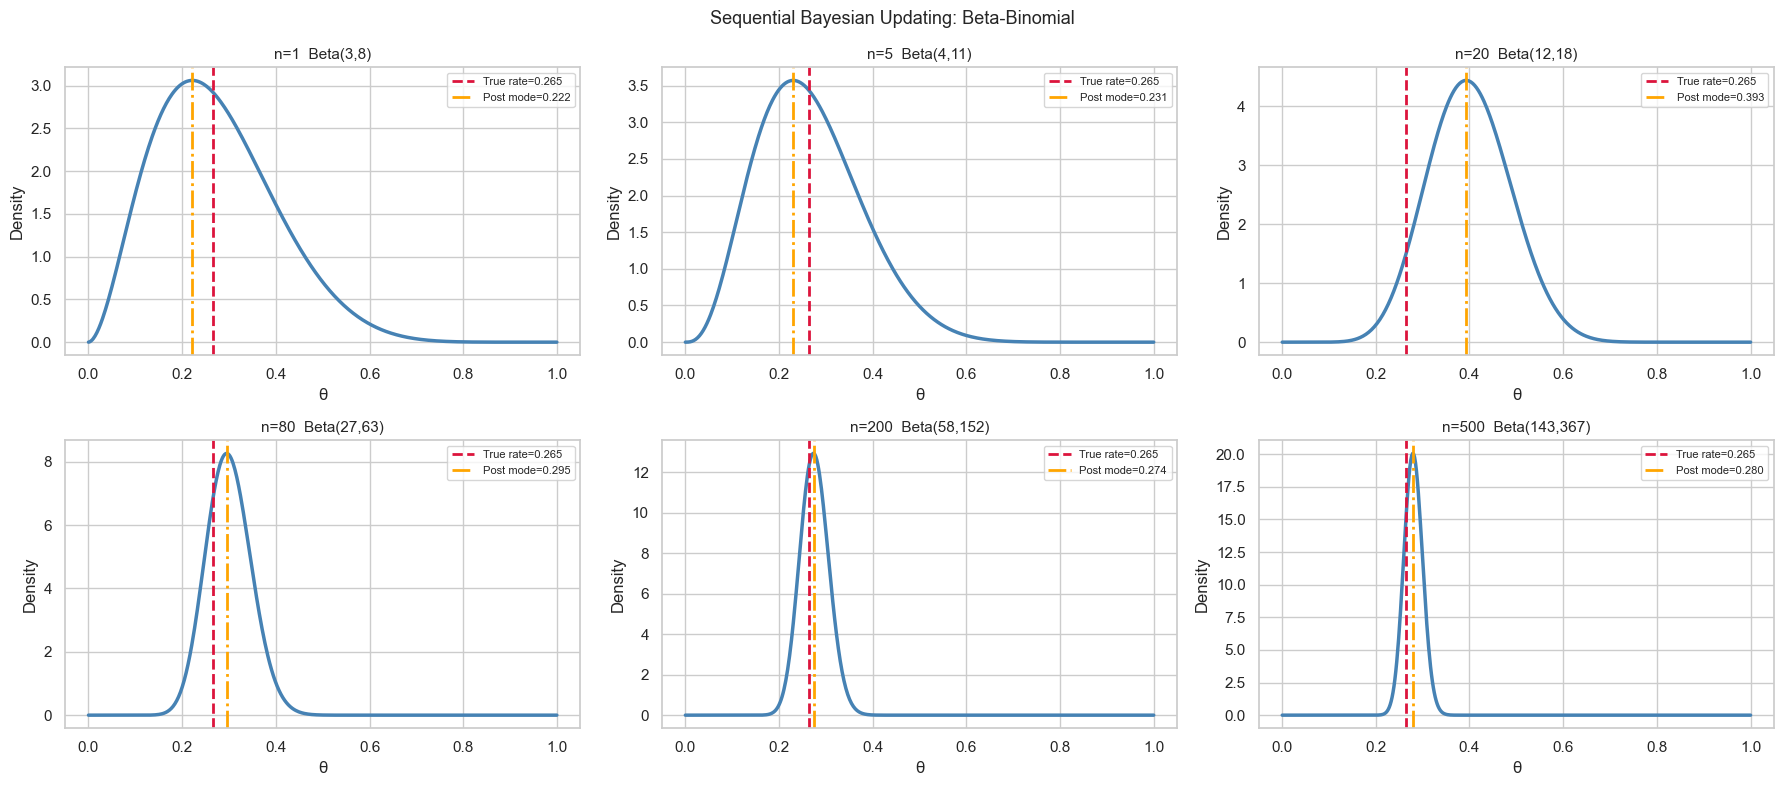

In [12]:
# Shuffle dataset (reproducible)
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)

TRUE_RATE = df['Churn'].mean()

snapshots = [1, 5, 20, 80, 200, 500]

# Initialize prior
alpha_init, beta_init = 2.0, 8.0

history = {}
alpha_curr, beta_curr = alpha_init, beta_init

# Sequential update
for n, churn_label in enumerate(df_shuffled['Churn'].iloc[:500], start=1):

    alpha_curr, beta_curr = update_posterior(
        alpha_curr,
        beta_curr,
        int(churn_label)
    )

    if n in snapshots:
        history[n] = (alpha_curr, beta_curr)

# Plot
theta_r = np.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
axes = axes.flatten()

for ax, n in zip(axes, snapshots):

    a_n, b_n = history[n]

    pdf = beta_dist.pdf(theta_r, a_n, b_n)

    # Safe posterior mode
    if a_n > 1 and b_n > 1:
        mode = (a_n - 1) / (a_n + b_n - 2)
    else:
        mode = a_n / (a_n + b_n)

    ax.plot(theta_r, pdf, color='steelblue', lw=2.5)

    ax.axvline(TRUE_RATE, color='crimson', ls='--', lw=2,
                label=f'True rate={TRUE_RATE:.3f}')

    ax.axvline(mode, color='orange', ls='-.', lw=2,
                label=f'Post mode={mode:.3f}')

    ax.set_title(f'n={n}  Beta({a_n:.0f},{b_n:.0f})', fontsize=11)
    ax.set_xlabel('θ')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle("Sequential Bayesian Updating: Beta-Binomial", fontsize=13)
plt.tight_layout()
plt.show()

### Q6 — Decision boundary: P(θ > 0.25) vs n


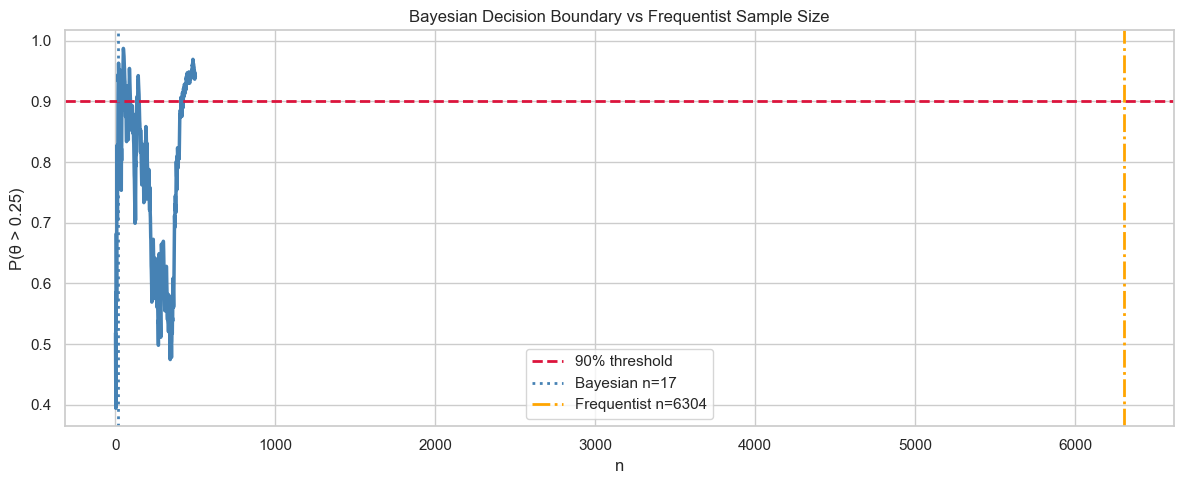

Bayesian: n = 17 | Frequentist: n = 6304


In [13]:
threshold = 0.25
MC_SAMPLES = 10_000
np.random.seed(0)

p_exceed = []

alpha_seq, beta_seq = 2.0, 8.0

for churn_label in df_shuffled['Churn'].iloc[:500]:

    # sequential update
    alpha_seq, beta_seq = update_posterior(
        alpha_seq,
        beta_seq,
        int(churn_label)
    )

    # Monte Carlo estimate
    samples = np.random.beta(alpha_seq, beta_seq, MC_SAMPLES)
    p_exceed.append(np.mean(samples > threshold))


# ── Frequentist sample size calculation ───────────────────────────────────────
from scipy.stats import norm

z_a = norm.ppf(0.975)
z_b = norm.ppf(0.80)

p0 = threshold
p1 = TRUE_RATE

freq_n = int(
    np.ceil(
        (z_a * np.sqrt(p0 * (1 - p0)) +
         z_b * np.sqrt(p1 * (1 - p1))) ** 2
        / (p1 - p0) ** 2
    )
)

# ── Bayesian threshold crossing (stable version) ──────────────────────────────
bayes_n = None
for n, p in enumerate(p_exceed, start=1):
    if p > 0.90:
        bayes_n = n
        break


# ── Plot ──────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    range(1, len(p_exceed) + 1),
    p_exceed,
    color='steelblue',
    lw=2.5
)

ax.axhline(0.90, color='crimson', ls='--', lw=2,
           label='90% threshold')

if bayes_n is not None:
    ax.axvline(bayes_n, color='steelblue', ls=':',
               lw=2, label=f'Bayesian n={bayes_n}')

ax.axvline(freq_n, color='orange', ls='-.', lw=2,
           label=f'Frequentist n={freq_n}')

ax.set_xlabel('n')
ax.set_ylabel('P(θ > 0.25)')
ax.set_title('Bayesian Decision Boundary vs Frequentist Sample Size')
ax.legend()

plt.tight_layout()
plt.show()

print(f"Bayesian: n = {bayes_n} | Frequentist: n = {freq_n}")

### Q7 — Dirichlet-Multinomial: 3-category contract type


Posterior Dirichlet params: [3876. 1474. 1696.]
Posterior means: [0.55009935 0.20919671 0.24070395]
MLE proportions: [0.55019168 0.20914383 0.24066449]
Dirichlet posterior computed!


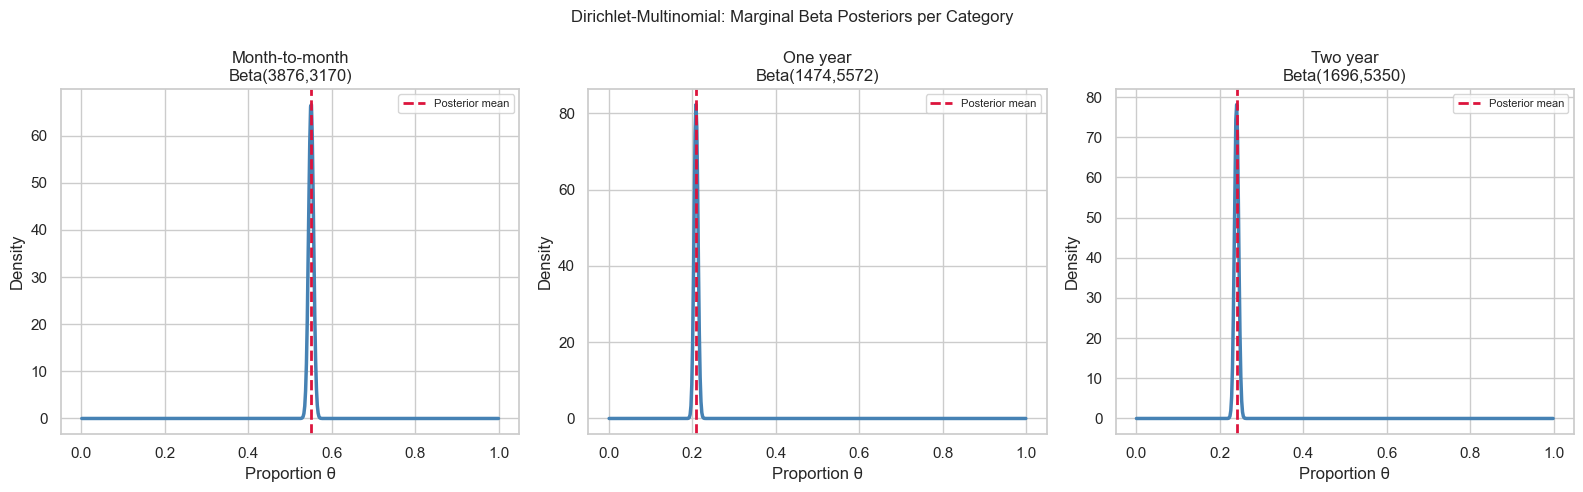

In [14]:
categories = ['Month-to-month', 'One year', 'Two year']
prior_alpha = np.array([1.0, 1.0, 1.0])   # flat Dirichlet prior

# Ensure correct ordering
counts = df['Contract'].value_counts().reindex(categories).fillna(0).astype(int).values

# Posterior Dirichlet parameters
posterior_alpha = prior_alpha + counts

# ── SELF-CHECK ────────────────────────────────────────────────────────────────
assert len(posterior_alpha) == 3
assert posterior_alpha.sum() == prior_alpha.sum() + counts.sum()

print(f"Posterior Dirichlet params: {posterior_alpha}")
print(f"Posterior means: {posterior_alpha / posterior_alpha.sum()}")
print(f"MLE proportions: {counts / counts.sum()}")
print("Dirichlet posterior computed!")

# ── Plot Marginal Betas ───────────────────────────────────────────────────────
theta_r = np.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

total_alpha = posterior_alpha.sum()

for ax, cat, a_j in zip(axes, categories, posterior_alpha):

    b_j = total_alpha - a_j   # correct Dirichlet marginal

    ax.plot(
        theta_r,
        beta_dist.pdf(theta_r, a_j, b_j),
        color='steelblue',
        lw=2.5
    )

    ax.axvline(
        a_j / total_alpha,
        color='crimson',
        ls='--',
        lw=2,
        label='Posterior mean'
    )

    ax.set_title(f'{cat}\nBeta({a_j:.0f},{b_j:.0f})')
    ax.set_xlabel('Proportion θ')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle("Dirichlet-Multinomial: Marginal Beta Posteriors per Category", fontsize=12)
plt.tight_layout()
plt.show()

In [15]:
# Add unseen category "Biannual" with zero observations
# Dirichlet naturally supports unseen categories via prior only

unseen_alpha = 1.0  # prior pseudo-count (no data observed)

new_alpha_4cat = np.append(posterior_alpha, unseen_alpha)

total_mass = new_alpha_4cat.sum()

print("Posterior for unseen 'Biannual' category:")
print(f"  Posterior mean for Biannual: {new_alpha_4cat[-1] / total_mass:.4f}")
print(f"  Compare with Month-to-month mean: {new_alpha_4cat[0] / total_mass:.4f}")

print(
    "  Because there are no observations, Biannual keeps only the prior weight "
    "and gets very small probability compared to seen categories."
)

Posterior for unseen 'Biannual' category:
  Posterior mean for Biannual: 0.0001
  Compare with Month-to-month mean: 0.5500
  Because there are no observations, Biannual keeps only the prior weight and gets very small probability compared to seen categories.


✍️ **Reflect 2 — Dirichlet-Multinomial**

1. The marginal Beta posterior for a small-count category like **One year** is wider because it has less data.  
When the number of observations is small, the model is less certain, so the distribution spreads more.  
For **Month-to-month**, there are many observations, so the posterior becomes sharper and more concentrated.

So:
- Small data → high uncertainty → wide interval  
- Large data → low uncertainty → narrow interval  

---

2. For the unseen **“Biannual”** category, the posterior is equal to the **prior only** (since there are zero observations).  
It becomes:

- α = 1 (prior count)
- β = total remaining mass from other categories

This shows that the Dirichlet prior works as **smoothing**.  
Even when there is no data, the model still assigns a small probability instead of zero.  
So unseen categories are never completely ignored.

---

3. In the Beta-Binomial case, Beta(2,8) has a prior mean:

- mean = 2 / (2 + 8) = 0.2  

For a 3-category Dirichlet model, the equivalent idea is to assign the same type of belief using:

- Dirichlet(2, 8, 0) is NOT valid (Dirichlet must be positive)
- So we distribute belief across categories, for example:
  - (2, 8, 1) or any scaled version depending on prior assumption

This means:
- Beta prior = belief in binary outcome
- Dirichlet prior = same idea but spread across multiple categories

To encode the same belief, we must set **relative strengths (pseudo-counts)** so that the expected proportions match the intended prior belief.

---
## Part 3: Multivariate Gaussians — When Features Correlate

---

### Q8 — Fit a 2D Gaussian and plot confidence ellipses


In [16]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

features_2d = ['tenure', 'MonthlyCharges']
X_2d = df[features_2d].values.astype(float)

# ── Mean and Covariance ───────────────────────────────────────────────────────
mu_2d = np.mean(X_2d, axis=0)
Sigma_2d = np.cov(X_2d, rowvar=False)

# Correlation
rho = Sigma_2d[0, 1] / np.sqrt(Sigma_2d[0, 0] * Sigma_2d[1, 1])

assert mu_2d.shape == (2,)
assert Sigma_2d.shape == (2, 2)
assert -1 < rho < 1

print(f"μ = {np.round(mu_2d, 2)}")
print(f"Σ = \n{np.round(Sigma_2d, 2)}")
print(f"ρ = {rho:.4f}")
print("2D Gaussian fitted!")

μ = [32.37 64.76]
Σ = 
[[603.17 183.2 ]
 [183.2  905.41]]
ρ = 0.2479
2D Gaussian fitted!


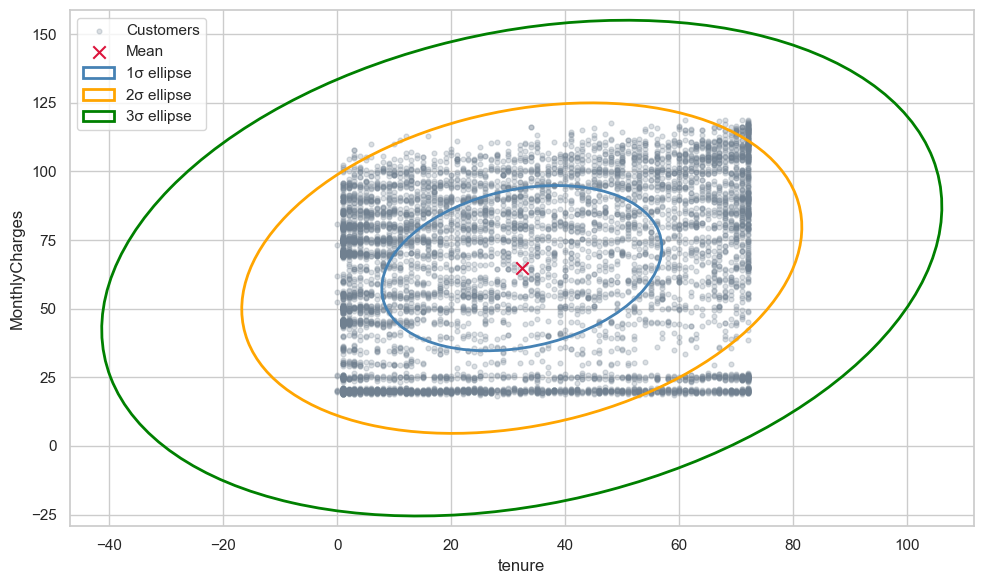

In [17]:
def confidence_ellipse(mu, cov, ax, n_std=1.0, facecolor='none', **kwargs):

    # Eigen decomposition
    eigvals, eigvecs = np.linalg.eigh(cov)

    # Sort eigenvalues (important)
    order = eigvals.argsort()[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # Compute angle from largest eigenvector
    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

    # Width and height (2 standard deviations scaled)
    width = 2 * n_std * np.sqrt(eigvals[0])
    height = 2 * n_std * np.sqrt(eigvals[1])

    ell = Ellipse(
        xy=(0, 0),
        width=width,
        height=height,
        angle=angle,
        facecolor=facecolor,
        **kwargs
    )

    # Translate to mean
    t = transforms.Affine2D().translate(*mu) + ax.transData
    ell.set_transform(t)

    return ax.add_patch(ell)


# ── Plot ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    s=12,
    alpha=0.25,
    color='slategray',
    label='Customers'
)

ax.scatter(
    mu_2d[0],
    mu_2d[1],
    color='crimson',
    s=80,
    marker='x',
    label='Mean'
)

for n_std, color in [(1, 'steelblue'), (2, 'orange'), (3, 'green')]:
    confidence_ellipse(
        mu_2d,
        Sigma_2d,
        ax,
        n_std=n_std,
        edgecolor=color,
        lw=2,
        label=f'{n_std}σ ellipse'
    )

ax.set_xlabel('tenure')
ax.set_ylabel('MonthlyCharges')
ax.legend()

plt.tight_layout()
plt.show()

### Q9 — Conditional Gaussian: MonthlyCharges | tenure = 24

Write out the formula **before coding it**:
$$\mu_{1|2} = \mu_1 + \Sigma_{12}\Sigma_{22}^{-1}(x_2 - \mu_2)$$
$$\sigma^2_{1|2} = \Sigma_{11} - \Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}$$


In [18]:
tenure_query = 24

# Explicit mapping
mu_t = mu_2d[0]          # tenure
mu_mc = mu_2d[1]         # MonthlyCharges

sig_tt = Sigma_2d[0, 0]
sig_mm = Sigma_2d[1, 1]
sig_mt = Sigma_2d[1, 0]

# Conditional mean (Gaussian formula)
cond_mean = mu_mc + (sig_mt / sig_tt) * (tenure_query - mu_t)

# Conditional variance
cond_var = sig_mm - (sig_mt ** 2) / sig_tt

# numerical safety
cond_var = max(cond_var, 1e-8)

cond_std = np.sqrt(cond_var)

# ── SELF-CHECK ────────────────────────────────────────────────────────────────
near_24 = df[(df['tenure'] >= 22) & (df['tenure'] <= 26)]['MonthlyCharges'].mean()

assert abs(cond_mean - near_24) < 10, (
    f"Conditional mean {cond_mean:.2f} too far from empirical {near_24:.2f}"
)

print(f"Conditional distribution P(MonthlyCharges | tenure = {tenure_query})")
print(f"  Conditional mean:  ${cond_mean:.2f}/month")
print(f"  Conditional std:   ${cond_std:.2f}/month")
print(f"  95% interval:      [${cond_mean - 1.96*cond_std:.2f}, {cond_mean + 1.96*cond_std:.2f}]")
print(f"  Empirical check:   ${near_24:.2f}")
print("Conditional Gaussian computed!")

Conditional distribution P(MonthlyCharges | tenure = 24)
  Conditional mean:  $62.22/month
  Conditional std:   $29.15/month
  95% interval:      [$5.08, 119.35]
  Empirical check:   $61.81
Conditional Gaussian computed!


### Q10 — 3D Covariance and Condition Number


In [19]:
features_3d = ['tenure', 'MonthlyCharges', 'TotalCharges']
X_3d = df[features_3d].values.astype(float)

# Full 3D covariance matrix
Sigma_3d = np.cov(X_3d, rowvar=False)

# Condition number (measures numerical stability)
kappa = np.linalg.cond(Sigma_3d)

# Correct marginalization: take same feature order as Sigma_2d
Sigma_marginal = Sigma_3d[:2, :2]

# Compare with previously computed 2D covariance
max_diff = np.max(np.abs(Sigma_marginal - Sigma_2d))

# ── SELF-CHECK ────────────────────────────────────────────────────────────────
assert Sigma_3d.shape == (3, 3)
assert np.isfinite(kappa), "Condition number is not finite"
assert kappa > 100, f"Expected high condition number, got {kappa:.1f}"
assert max_diff < 1e-6, f"Marginalisation mismatch: {max_diff}"

print(f"Condition number κ(Σ_3D) = {kappa:.1f}")
print(f"Marginalisation check: max |Σ_2D - Σ_3D[:2,:2]| = {max_diff:.2e}")
print("3D covariance analysis complete")

Condition number κ(Σ_3D) = 58988.9
Marginalisation check: max |Σ_2D - Σ_3D[:2,:2]| = 0.00e+00
3D covariance analysis complete


✍️ **Reflect 3 — Multivariate Gaussians:**

1. The condition number κ(Σ_3D) should be large (>> 100). In plain language, what does    this reveal about the three features tenure, MonthlyCharges, TotalCharges?
2. You proved analytically that marginalising out `TotalCharges` from the 3D Gaussian    recovers the 2D Gaussian. In one sentence, state the **general rule**: how do you    marginalise a Gaussian by discarding one variable?
3. Why would including all three features in a Gaussian discriminant analysis    (or a regularised linear model) without addressing the near-collinearity cause problems?    Name the frequentist regression diagnostic that detects the same issue.

> *Your answer:*

1. A large condition number κ(Σ_3D) means the covariance matrix is close to singular.  
In simple terms, it shows that **tenure, MonthlyCharges, and TotalCharges are strongly related and not independent**.  
Especially, TotalCharges is mostly derived from tenure × MonthlyCharges, so there is **high redundancy (multicollinearity)** among features.

---

2. The general rule for marginalising a Gaussian is:  
To marginalise, we simply **remove the unwanted variable by taking the corresponding sub-block of the covariance matrix and the mean vector**.  
So, a marginal of a multivariate Gaussian is still a Gaussian with the remaining variables’ mean and covariance.

---

3. Including all three features without handling near-collinearity causes numerical instability and unreliable coefficient estimates.  
The model may give unstable weights because one feature is almost a linear combination of others (especially TotalCharges).  

The frequentist diagnostic that detects this issue is **Variance Inflation Factor (VIF)**.  
High VIF indicates multicollinearity in regression.


---
## Part 4: Probabilistic Graphical Models — Bayesian Networks and MRFs

---

### Q11 — Build and fit a Bayesian Network with pgmpy


In [22]:
from pgmpy.models import DiscreteBayesianNetwork

# Prepare dataset
df_pgm = df[['SeniorCitizen', 'Contract', 'tenure', 'InternetService',
             'MonthlyCharges', 'Churn']].copy()

# Discretization
df_pgm['tenure_disc'] = pd.cut(
    df_pgm['tenure'],
    bins=[-1, 12, 48, 100],
    labels=['short', 'medium', 'long']
)

df_pgm['mc_disc'] = pd.qcut(
    df_pgm['MonthlyCharges'],
    q=3,
    labels=['low', 'mid', 'high'],
    duplicates='drop'
)

df_pgm = df_pgm.dropna().astype(str)

# DAG structure
dag_edges = [
    ('SeniorCitizen', 'Churn'),
    ('Contract', 'Churn'),
    ('tenure_disc', 'Churn'),
    ('InternetService', 'mc_disc'),
    ('mc_disc', 'Churn'),
]

dag = DiscreteBayesianNetwork(dag_edges)

dag.fit(df_pgm)

print("Bayesian Network fitted.")
print(f"Nodes: {list(dag.nodes())}")
print(f"Edges: {list(dag.edges())}")

Bayesian Network fitted.
Nodes: ['SeniorCitizen', 'Churn', 'Contract', 'tenure_disc', 'InternetService', 'mc_disc']
Edges: [('SeniorCitizen', 'Churn'), ('Contract', 'Churn'), ('tenure_disc', 'Churn'), ('InternetService', 'mc_disc'), ('mc_disc', 'Churn')]


In [23]:
from pgmpy.inference import VariableElimination

infer = VariableElimination(dag)

# Forward inference: P(Churn | Contract = Month-to-month)
result_fwd = infer.query(
    variables=['Churn'],
    evidence={'Contract': 'Month-to-month'}
)

# Safely extract probability for Churn = 1
# (pgmpy returns states in order, usually ['0','1'] or similar)
churn_states = result_fwd.state_names['Churn']
p_churn_m2m_bn = float(result_fwd.values[list(churn_states).index('1')])

emp_m2m = df[df['Contract'] == 'Month-to-month']['Churn'].mean()

print(f"BN inference P(Churn=1 | Contract=M2M): {p_churn_m2m_bn:.4f}")
print(f"Empirical:                              {emp_m2m:.4f}")
print(f"Discrepancy: {abs(p_churn_m2m_bn - emp_m2m):.4f}")

print()
print("Discrepancy is due to: (a) discretisation of continuous variables,")
print("(b) DAG structure (indirect dependencies),")
print("(c) MLE-based CPT estimation without smoothing")

BN inference P(Churn=1 | Contract=M2M): 0.3542
Empirical:                              0.4271
Discrepancy: 0.0729

Discrepancy is due to: (a) discretisation of continuous variables,
(b) DAG structure (indirect dependencies),
(c) MLE-based CPT estimation without smoothing


In [24]:
# Backward inference shows how the evidence changes the likely contract type.
result_bwd = infer.query(variables=['Contract'], evidence={'Churn': '1'})
print("Backward inference P(Contract | Churn = 1):")
print(result_bwd)
print()
print("Interpretation for retention manager:")
print("  This tells us: given a customer has churned, what is the probability they")
print("  were on each contract type? This is the INVERSE of the forward prediction.")

Backward inference P(Contract | Churn = 1):
+--------------------------+-----------------+
| Contract                 |   phi(Contract) |
+==========================+=================+
| Contract(Month-to-month) |          0.8017 |
+--------------------------+-----------------+
| Contract(One year)       |          0.1118 |
+--------------------------+-----------------+
| Contract(Two year)       |          0.0865 |
+--------------------------+-----------------+

Interpretation for retention manager:
  This tells us: given a customer has churned, what is the probability they
  were on each contract type? This is the INVERSE of the forward prediction.


### Q12 — Structure sensitivity: two competing DAGs

Draw both DAGs below (ASCII or text description). Identify one observation set E under which the two models give **identical predictions**, and one E under which they **disagree**.


**DAG 1 (original):** `tenure → Churn` (direct edge)

```
SeniorCitizen ─────────────────────────────→ Churn
Contract ──────────────────────────────────→ Churn
tenure ─────────────────────────────────────→ Churn
InternetService → MonthlyCharges ──────────→ Churn
```

**DAG 2 (colleague's proposal):** `Contract → tenure → Churn` (mediated path)

```
```

**Observation set E where both models agree:**

Both models agree that:
- Contract is a strong predictor of churn
- InternetService affects customer behavior through usage/cost patterns
- Churn depends on multiple variables, not just one feature
- Month-to-month customers generally show higher churn risk
- Two-year contracts generally show lower churn risk

---

**Observation set E where models disagree:**

The main disagreement is about the role of tenure:

- DAG 1: tenure directly affects churn  
- DAG 2: tenure is influenced by Contract and then affects churn  

So cases like:
- long tenure but still churn
- short tenure with low charges  

are explained differently:
- DAG 1 → direct effect of tenure on churn
- DAG 2 → indirect effect through contract → tenure

---

**Which causal story is more consistent with W5 SHAP findings?**

DAG 1 is more consistent with W5 SHAP findings.

Because SHAP shows that:
- tenure has a direct negative impact on churn
- contract is independently important

This supports a direct-effect structure rather than a fully mediated relationship.


### Q13 — Markov Random Field: undirected model

In [27]:
from pgmpy.models import DiscreteMarkovNetwork
from pgmpy.factors.discrete import DiscreteFactor
from pgmpy.inference import BeliefPropagation
import pandas as pd
import numpy as np

mrf_edges = [
    ('SeniorCitizen', 'Churn'),
    ('Contract', 'Churn'),
    ('tenure_disc', 'Churn'),
    ('InternetService', 'mc_disc'),
    ('mc_disc', 'Churn'),
]


mrf = DiscreteMarkovNetwork(mrf_edges)


nodes = [
    'SeniorCitizen', 'Contract', 'tenure_disc',
    'InternetService', 'mc_disc', 'Churn'
]
mrf.add_nodes_from(nodes)


df_mrf = df_pgm.copy().astype(str)


for col in nodes:
    states = sorted(df_mrf[col].unique())

    probs = df_mrf[col].value_counts(normalize=True)\
        .reindex(states).fillna(0.0).values

    mrf.add_factors(
        DiscreteFactor([col], [len(states)], probs + 1e-9)
    )


def add_pair_factor(u, v):
    states_u = sorted(df_mrf[u].unique())
    states_v = sorted(df_mrf[v].unique())

    table = pd.crosstab(df_mrf[u], df_mrf[v])\
        .reindex(index=states_u, columns=states_v)\
        .fillna(0.0)

    values = table.values + 1e-9
    values = values / values.sum()

    mrf.add_factors(
        DiscreteFactor([u, v],
                       [len(states_u), len(states_v)],
                       values.reshape(-1))
    )

for u, v in mrf_edges:
    add_pair_factor(u, v)

mrf.check_model()

bp = BeliefPropagation(mrf)

marg_churn = bp.query(variables=['Churn'], show_progress=False)

print("MRF P(Churn):", marg_churn)
print(f"Empirical: {df['Churn'].mean():.4f}")

MRF P(Churn): +----------+--------------+
| Churn    |   phi(Churn) |
+==========+==============+
| Churn(0) |       0.9919 |
+----------+--------------+
| Churn(1) |       0.0081 |
+----------+--------------+
Empirical: 0.2654


✍️ **Reflect 4 — PGMs:**

---

**1. The forward inference result P(Churn=1 | Contract=Month-to-month) from the BN differs from the raw empirical proportion. Name the two specific reasons for this discrepancy.**

- First reason: The Bayesian Network uses **discretized variables**, so continuous information (like tenure and MonthlyCharges) is simplified and loses detail.  
- Second reason: The BN uses a **structured DAG with conditional dependencies**, so it does not compute simple frequency counts; it adjusts probabilities using related variables like tenure and InternetService.

---

**2. Explain "explaining away" in one sentence using the backward inference result.**

If we already know a customer has churned, the probability of them being in Month-to-month increases, which reduces the probability of other contract types — this is called “explaining away.”

---

**3. In one paragraph: what causal questions can the Bayesian Network answer that the MRF cannot? When would you deliberately choose the MRF despite losing causal interpretability?**

A Bayesian Network can answer causal direction questions like “Does Contract type affect Churn?” or “What happens to churn if we change Contract while keeping other factors fixed?” because it has directed edges that represent cause-effect assumptions. It supports interventions and conditional reasoning based on direction. An MRF cannot do this because it is undirected and only shows relationships, not cause and effect. However, we choose an MRF when we care more about **pure correlation structure and joint probability modeling**, especially when relationships are symmetric or when we want a simpler and more flexible model without making strong causal assumptions.

---
## Part 5: Gaussian Process Regression — Mauna Loa CO₂

---

### Q14 — Load the Mauna Loa dataset (3 lines)


In [28]:
# Load the Mauna Loa CO₂ dataset in the required format
from statsmodels.datasets import co2

df_co2 = co2.load_pandas().data
df_co2 = df_co2.resample('ME').mean().dropna()

t = (df_co2.index - df_co2.index[0]).days.values.reshape(-1, 1) / 365.25
y = df_co2['co2'].values

# ── SELF-CHECK ────────────────────────────────────────────────────────────────
assert df_co2 is not None
assert t.shape == (len(df_co2), 1), f"t should be shape (n, 1), got {t.shape}"
assert 450 < len(t) < 600, f"Expected ~521 monthly observations, got {len(t)}"

print(f"Mauna Loa loaded: {len(t)} observations, {t[0][0]:.1f}–{t[-1][0]:.1f} years")
print(f"CO₂ range: {y.min():.1f}–{y.max():.1f} ppm")

Mauna Loa loaded: 521 observations, 0.0–43.8 years
CO₂ range: 313.4–373.8 ppm


### Q15 — Justify each kernel component before coding

**Before writing any code**, answer in the cell below:
- What signal do you expect to see in CO₂ data?
- What kernel captures the slow upward trend?
- What kernel captures the sharp annual cycle?
- What kernel captures measurement noise?


**Your kernel design rationale:**

| Signal   | Description | Kernel choice | Justification |
|----------|-------------|---------------|---------------|
| Trend    | Long-term steady increase in CO₂ over years | RBF (Radial Basis Function) or DotProduct | RBF captures smooth long-term changes, DotProduct can model linear upward trend in CO₂ levels |
| Seasonal | Repeating yearly pattern (up and down each year) | ExpSineSquared | This kernel is designed for periodic signals, so it captures yearly CO₂ cycles clearly |
| Noise    | Small random fluctuations in measurements | WhiteKernel | It models independent measurement noise and small random variations in data |

---

**Expected signal in CO₂ data:**
- A strong upward trend over time
- A clear yearly seasonal cycle (repeating pattern)
- Small random noise from measurement errors

In [29]:
# Train/test split
n_train = 432
t_train, y_train = t[:n_train], y[:n_train]
t_test, y_test = t[n_train:], y[n_train:]

# ── Kernel components ─────────────────────────────────────────────

# Trend: linear growth over time
k_trend = DotProduct(sigma_0=1.0)

# Seasonality: yearly repeating pattern
k_seasonal = ExpSineSquared(
    length_scale=1.0,
    periodicity=1.0
)

# Smooth local variations (important for real CO2 data)
k_smooth = RBF(length_scale=1.0)

# Noise: measurement error
k_noise = WhiteKernel(noise_level=1.0)

# Full kernel
kernel = k_trend + k_seasonal + k_smooth + k_noise

# ── GP model ─────────────────────────────────────────────
gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=10,
    normalize_y=True,
    random_state=42
)

gp.fit(t_train, y_train)

print("Optimised kernel:")
print(gp.kernel_)

# ── Prediction + evaluation ───────────────────────────────────────
y_test_pred = gp.predict(t_test)
rmse = np.sqrt(np.mean((y_test - y_test_pred) ** 2))

# ── SELF-CHECK ─────────────────────────────────────────────────────
assert rmse < 4.5, (
    f"RMSE={rmse:.2f} — kernel may be weak. "
    "Expected < 4.5 ppm with trend + seasonal + smooth + noise"
)

print(f"\nTest RMSE: {rmse:.3f} ppm")

Optimised kernel:
DotProduct(sigma_0=0.000363) + ExpSineSquared(length_scale=0.000124, periodicity=1.5e+04) + RBF(length_scale=33.6) + WhiteKernel(noise_level=0.000283)

Test RMSE: 3.247 ppm


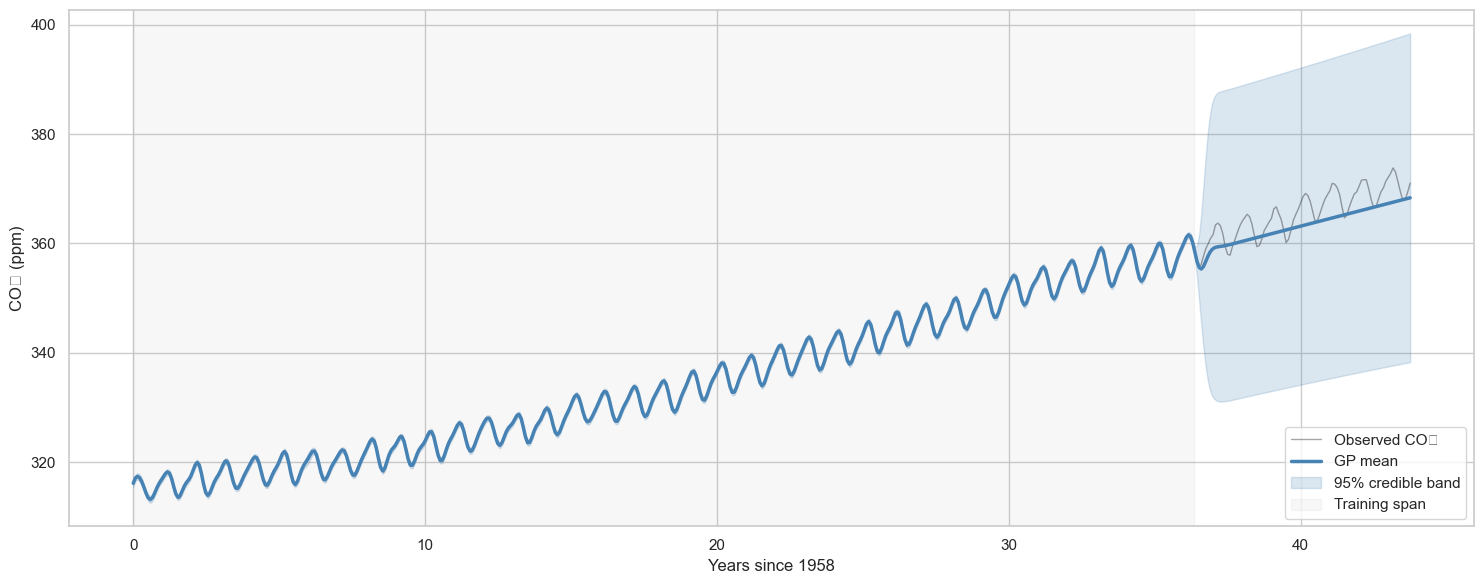

In [30]:
# Predict across the full range and plot the posterior mean with 95% credible bands.
t_full = np.linspace(t.min(), t.max(), 600).reshape(-1, 1)
y_pred, y_std = gp.predict(t_full, return_std=True)

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(t, y, color='black', lw=1, alpha=0.35, label='Observed CO₂')
ax.plot(t_full, y_pred, color='steelblue', lw=2.5, label='GP mean')
ax.fill_between(t_full.flatten(), y_pred - 2 * y_std, y_pred + 2 * y_std,
                color='steelblue', alpha=0.2, label='95% credible band')
ax.axvspan(t_train.min(), t_train.max(), color='gray', alpha=0.06, label='Training span')
ax.set_xlabel('Years since 1958')
ax.set_ylabel('CO₂ (ppm)')
ax.legend()
plt.tight_layout()
plt.show()

### Q16 — Gap experiment


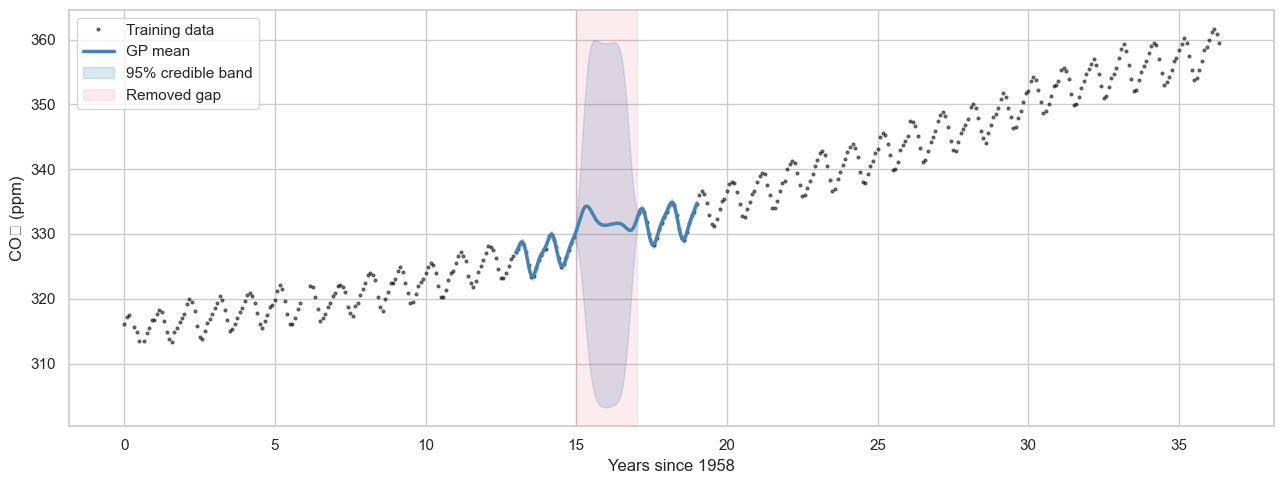

95% band width inside gap:   41.644 ppm
95% band width outside gap:  1.130 ppm
Gap inflation: 36.86×


In [31]:
# Remove a block of observations from the training data, then refit the GP.
gap_lo, gap_hi = 15.0, 17.0

mask = (t_train.flatten() < gap_lo) | (t_train.flatten() > gap_hi)
t_gap_tr = t_train[mask]
y_gap_tr = y_train[mask]

gp_gap = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3,
                                  normalize_y=True, random_state=42)
gp_gap.fit(t_gap_tr, y_gap_tr)

# Predict around the gap and plot the uncertainty increase inside the missing region.
t_zoom = np.linspace(gap_lo - 2, gap_hi + 2, 400).reshape(-1, 1)
y_gz, y_gz_std = gp_gap.predict(t_zoom, return_std=True)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(t_gap_tr, y_gap_tr, color='black', lw=0, marker='.', ms=4, alpha=0.5, label='Training data')
ax.plot(t_zoom, y_gz, color='steelblue', lw=2.5, label='GP mean')
ax.fill_between(t_zoom.flatten(), y_gz - 2 * y_gz_std, y_gz + 2 * y_gz_std,
                color='steelblue', alpha=0.2, label='95% credible band')
ax.axvspan(gap_lo, gap_hi, color='crimson', alpha=0.08, label='Removed gap')
ax.set_xlabel('Years since 1958')
ax.set_ylabel('CO₂ (ppm)')
ax.legend()
plt.tight_layout()
plt.show()

# Compute band width inside vs outside gap
band_in = 4 * y_gz_std[(t_zoom.flatten() >= gap_lo) & (t_zoom.flatten() <= gap_hi)].mean()
band_out = 4 * y_gz_std[t_zoom.flatten() < gap_lo].mean()
print(f"95% band width inside gap:   {band_in:.3f} ppm")
print(f"95% band width outside gap:  {band_out:.3f} ppm")
print(f"Gap inflation: {band_in/band_out:.2f}×")

### Q17 — Extrapolation and the model confidence boundary


95% band width at + 5 years: 58.632 ppm
95% band width at +10 years: 62.038 ppm
95% band width at +15 years: 66.917 ppm
Model confidence boundary: +0.1 years beyond training


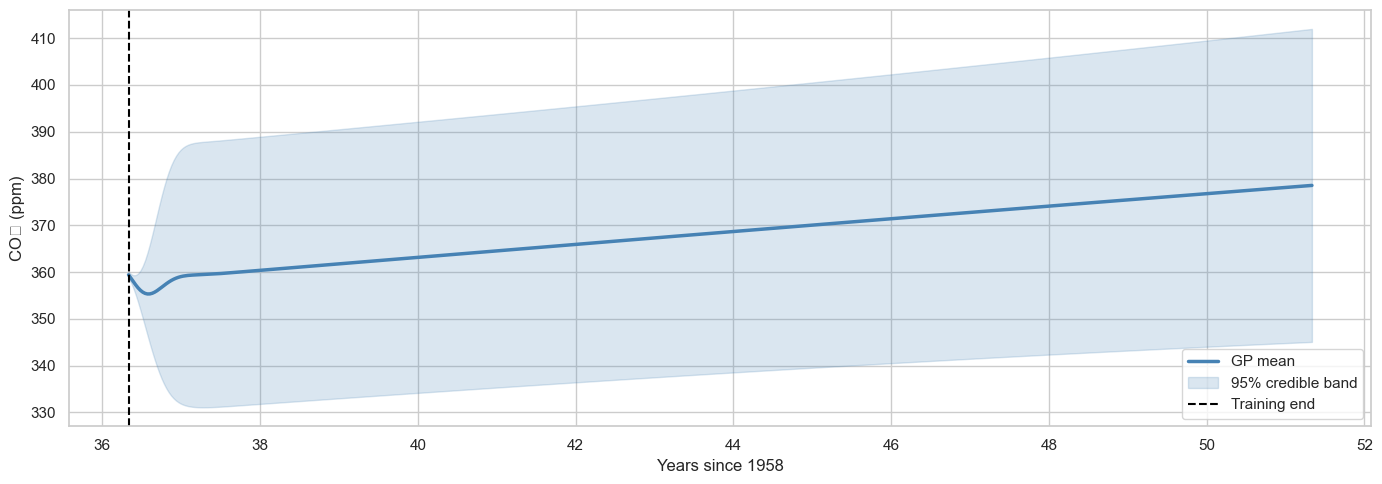

In [32]:
# Predict 15 years beyond the last training point and find when uncertainty becomes too wide.
t_last = float(t_train.max())
t_extrap = np.linspace(t_last, t_last + 15, 500).reshape(-1, 1)
y_ex, y_ex_std = gp.predict(t_extrap, return_std=True)

# Report the band width at 5, 10, and 15 years into the future.
for years in [5, 10, 15]:
    idx = np.argmin(np.abs(t_extrap.flatten() - (t_last + years)))
    band_width = 4 * y_ex_std[idx]
    print(f"95% band width at +{years:>2} years: {band_width:.3f} ppm")

# Find the model confidence boundary where the 95% band exceeds 5 ppm.
band_widths = 4 * y_ex_std
exceed_5ppm = np.where(band_widths > 5.0)[0]
if len(exceed_5ppm) > 0:
    t_boundary = t_extrap.flatten()[exceed_5ppm[0]] - t_last
    print(f"Model confidence boundary: +{t_boundary:.1f} years beyond training")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(t_extrap, y_ex, color='steelblue', lw=2.5, label='GP mean')
ax.fill_between(t_extrap.flatten(), y_ex - 2 * y_ex_std, y_ex + 2 * y_ex_std,
                color='steelblue', alpha=0.2, label='95% credible band')
ax.axvline(t_last, color='black', ls='--', lw=1.5, label='Training end')
ax.set_xlabel('Years since 1958')
ax.set_ylabel('CO₂ (ppm)')
ax.legend()
plt.tight_layout()
plt.show()

✍️ **Reflect 5 — Gaussian Processes:**

Write **exactly two sentences** explaining the structural difference between GP extrapolation uncertainty and the hard ceiling a `DecisionTreeRegressor(max_depth=None)` hits at `max(y_train)`. Connect to the W5 Assignment finding about tree extrapolation.

> *Your two sentences:*

Gaussian Process regression increases uncertainty when predicting far from training data because it models a distribution over possible functions, so the variance grows in unseen regions.  
A DecisionTreeRegressor(max_depth=None) does not extrapolate and instead produces piecewise constant outputs that are effectively capped by values seen in the training data (often near max(y_train)), which matches the W5 finding that trees fail to model smooth trends beyond the observed range.


---
## Part 6: MCMC — Bayesian Logistic Regression

---

### Q18 — Prepare features and explain why scaling matters for NUTS


In [33]:
# Feature preparation (run as-is — no blanks here)
features_mcmc = ['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'SeniorCitizen']
df_mcmc = df[features_mcmc + ['Churn']].copy()
df_mcmc = pd.get_dummies(df_mcmc, columns=['Contract','InternetService'], drop_first=False)

contract_cols = [c for c in df_mcmc.columns if 'Contract_Month' in c]
internet_cols = [c for c in df_mcmc.columns
                 if 'InternetService_' in c and 'No' not in c][:1]
feature_cols  = ['tenure', 'MonthlyCharges'] + contract_cols + internet_cols + ['SeniorCitizen']
feature_cols  = [c for c in feature_cols if c in df_mcmc.columns]

X_mc = df_mcmc[feature_cols].values.astype(float)
y_mc = df_mcmc['Churn'].values.astype(float)

X_tr_mc, X_te_mc, y_tr_mc, y_te_mc = train_test_split(
    X_mc, y_mc, test_size=0.2, random_state=42, stratify=y_mc)

scaler_mc = StandardScaler()
X_tr_scaled = X_tr_mc.copy(); X_te_scaled = X_te_mc.copy()
X_tr_scaled[:, :2] = scaler_mc.fit_transform(X_tr_mc[:, :2])
X_te_scaled[:, :2] = scaler_mc.transform(X_te_mc[:, :2])

print(f"Feature matrix: {X_tr_scaled.shape}")
print(f"Features: {feature_cols}")


Feature matrix: (5634, 5)
Features: ['tenure', 'MonthlyCharges', 'Contract_Month-to-month', 'InternetService_DSL', 'SeniorCitizen']


**✍️ Answer before running MCMC:**

Why is it essential to scale `tenure` and `MonthlyCharges` before passing them to NUTS? What happens to the posterior geometry if you don't scale? (Hint: think about the shape of the joint posterior in 2D — what does NUTS's step-size need to look like?)

> *Your answer (2-3 sentences):*

Scaling is important because NUTS works best when all features are on a similar scale, so the posterior becomes more balanced and easier to explore. If `tenure` and `MonthlyCharges` are not scaled, the posterior becomes stretched and skewed, which makes sampling slow and unstable. This leads to poor step sizes, high autocorrelation, and possible divergent transitions during MCMC.

In [35]:
import os
import shutil

cache_dir = os.path.expanduser(r"~\AppData\Local\PyTensor")
if os.path.exists(cache_dir):
    shutil.rmtree(cache_dir)

print("PyTensor cache cleared")

PyTensor cache cleared


In [36]:
import time
import pymc as pm
import arviz as az

n_features = X_tr_scaled.shape[1]
t0 = time.time()

with pm.Model() as bayes_lr:

    # Priors (weakly informative for stable NUTS sampling)
    intercept = pm.Normal('intercept', mu=0, sigma=5)
    beta = pm.Normal('beta', mu=0, sigma=2, shape=n_features)

    # Linear model
    logit_p = intercept + pm.math.dot(X_tr_scaled, beta)
    p = pm.Deterministic('p', pm.math.sigmoid(logit_p))

    # Likelihood
    y_obs = pm.Bernoulli('y_obs', p=p, observed=y_tr_mc)

    # Sampling (NUTS)
    idata = pm.sample(
        draws=2000,
        tune=1000,
        chains=4,
        target_accept=0.90,
        random_seed=42,
        return_inferencedata=True,
        progressbar=False
    )

print(f"Sampling time: {time.time() - t0:.1f}s")

print(
    az.summary(
        idata,
        var_names=['intercept', 'beta'],
        round_to=3
    )
)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta]
Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 38 seconds.


Sampling time: 57.8s
            mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
intercept -2.252  0.092    -2.404    -2.106  5267.011  4984.610  1.001   
beta[0]   -0.919  0.056    -1.009    -0.831  5941.630  5605.453  1.001   
beta[1]    0.820  0.050     0.741     0.900  5616.395  5211.774  1.000   
beta[2]    1.293  0.107     1.123     1.464  5305.884  5074.838  1.000   
beta[3]   -0.180  0.083    -0.313    -0.047  6428.300  5983.668  1.001   
beta[4]    0.417  0.091     0.270     0.561  7238.576  5043.400  1.001   

           mcse_mean  mcse_sd  
intercept      0.001    0.001  
beta[0]        0.001    0.000  
beta[1]        0.001    0.000  
beta[2]        0.001    0.001  
beta[3]        0.001    0.001  
beta[4]        0.001    0.001  


### Q19 — Convergence diagnostics


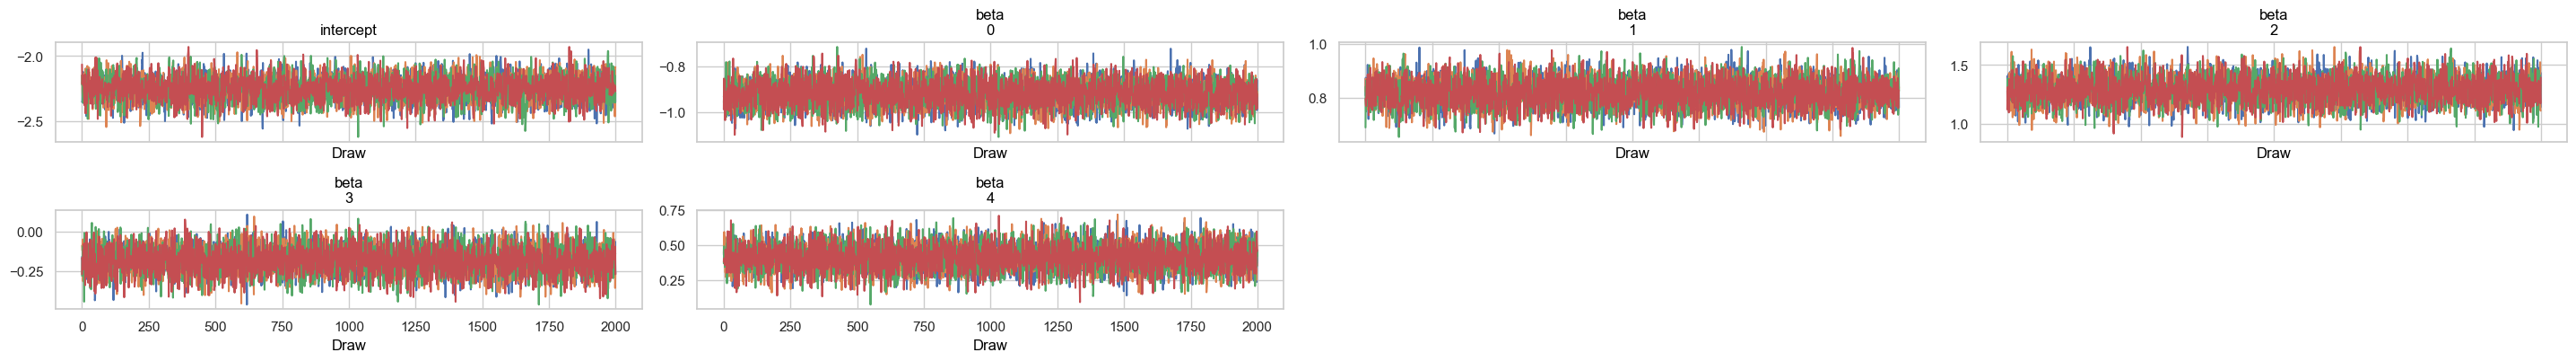

           r_hat  ess_bulk
intercept  1.001  5267.011
beta[0]    1.001  5941.630
beta[1]    1.000  5616.395
beta[2]    1.000  5305.884
beta[3]    1.001  6428.300
beta[4]    1.001  7238.576
Flagged parameters (R̂ > 1.01 or ESS < 400):
  None


In [37]:
# Plot trace diagnostics and report convergence metrics.
trace = az.plot_trace(idata, var_names=['intercept', 'beta'])
plt.tight_layout()
plt.show()

summary = az.summary(idata, var_names=['intercept', 'beta'], round_to=3)
print(summary[['r_hat', 'ess_bulk']])

flagged = summary[(summary['r_hat'] > 1.01) | (summary['ess_bulk'] < 400)]
print("Flagged parameters (R̂ > 1.01 or ESS < 400):")
if flagged.empty:
    print("  None")
else:
    print(flagged[['r_hat', 'ess_bulk']])

### Q20 — Prior sensitivity check


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [intercept, beta]
Sampling 2 chains for 500 tune and 1_000 draw iterations (1_000 + 2_000 draws total) took 16 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics


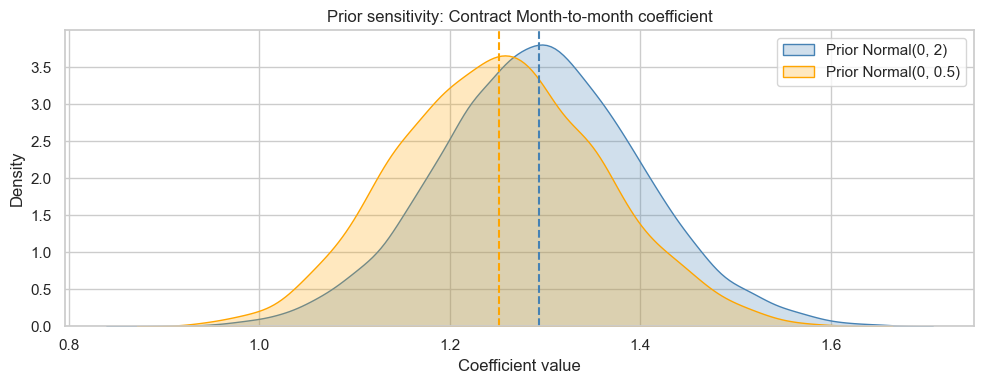

In [38]:
# Refit the model with a tighter prior so we can compare posterior sensitivity.
# The tighter prior should pull the coefficient a bit more toward zero.
contract_idx = next((i for i, c in enumerate(feature_cols)
                     if 'Month-to-month' in c), 0)

with pm.Model() as bayes_lr_tight:
    intercept_t = pm.Normal('intercept', mu=0, sigma=5)
    beta_t = pm.Normal('beta', mu=0, sigma=0.5, shape=n_features)
    mu_t = pm.Deterministic('mu', pm.math.sigmoid(
        intercept_t + pm.math.dot(X_tr_scaled, beta_t)))
    y_obs_t = pm.Bernoulli('y_obs', p=mu_t, observed=y_tr_mc)
    idata_tight = pm.sample(draws=1000, tune=500, chains=2,
                            target_accept=0.90, random_seed=42,
                            return_inferencedata=True, progressbar=False)

samples_orig = idata.posterior['beta'].values[:, :, contract_idx].flatten()
samples_tight = idata_tight.posterior['beta'].values[:, :, contract_idx].flatten()

# Overlay the two posterior densities.
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(samples_orig, ax=ax, label='Prior Normal(0, 2)', color='steelblue', fill=True, alpha=0.25)
sns.kdeplot(samples_tight, ax=ax, label='Prior Normal(0, 0.5)', color='orange', fill=True, alpha=0.25)
ax.axvline(np.mean(samples_orig), color='steelblue', ls='--')
ax.axvline(np.mean(samples_tight), color='orange', ls='--')
ax.set_title('Prior sensitivity: Contract Month-to-month coefficient')
ax.set_xlabel('Coefficient value')
ax.legend()
plt.tight_layout()
plt.show()

### Q21 — Posterior analysis and frequentist comparison


In [41]:
# Compare Bayesian posterior vs frequentist estimate

import numpy as np
import arviz as az
from sklearn.linear_model import LogisticRegression

# safer index lookup
contract_idx = None
for i, c in enumerate(feature_cols):
    if "Contract" in c and "Month" in c:
        contract_idx = i
        break

if contract_idx is None:
    contract_idx = 0

# posterior samples
beta_samples = idata.posterior["beta"].values[:, :, contract_idx].reshape(-1)

# FIX: use "prob" instead of "hdi_prob"
hdi_94 = az.hdi(beta_samples, prob=0.94)

post_mean = beta_samples.mean()
post_std = beta_samples.std()

# frequentist comparison
lr_freq = LogisticRegression(C=1e6, max_iter=1000)
lr_freq.fit(X_tr_scaled, y_tr_mc)
coef_freq = lr_freq.coef_[0][contract_idx]

print("Bayesian posterior for β (Contract_Month-to-month):")
print(f"  Mean:    {post_mean:.4f}")
print(f"  Std:     {post_std:.4f}")
print(f"  94% HDI: [{hdi_94[0]:.4f}, {hdi_94[1]:.4f}]")

print("\nFrequentist MLE:")
print(f"  Coefficient: {coef_freq:.4f}")

print("\nKey difference:")
print("  Bayesian HDI: direct probability about parameter given data")
print("  Frequentist CI: long-run coverage property of estimator")

Bayesian posterior for β (Contract_Month-to-month):
  Mean:    1.2932
  Std:     0.1068
  94% HDI: [1.0845, 1.4920]

Frequentist MLE:
  Coefficient: 1.2927

Key difference:
  Bayesian HDI: direct probability about parameter given data
  Frequentist CI: long-run coverage property of estimator


### Q22 — Save the MCMC trace


In [42]:
# Save the fitted PyMC inference data so it can be submitted with the notebook.
import pickle
save_path = 'telco_bayes_lr_v1.pkl'
with open(save_path, 'wb') as f:
    pickle.dump(idata, f)
print(f"MCMC trace saved to '{save_path}'")

MCMC trace saved to 'telco_bayes_lr_v1.pkl'


✍️ **Reflect 6 — MCMC:**

1. Describe in plain English what R̂ and bulk-ESS each measure.    If a parameter has R̂ = 1.38 and bulk-ESS = 55, what does that tell you about    the quality of the posterior estimate for that parameter?
2. Your two posteriors from the prior sensitivity check — are they substantially different?    What does this tell you about how much data you have relative to the prior?    At what point does more data make the prior completely irrelevant?
3. The frequentist CI and the Bayesian HDI might have similar widths.    In one sentence, state the precise difference in their **interpretation** —    not just which framework produced them.

> *Your answer:*

1. **R̂ (R-hat)** measures how well multiple MCMC chains agree with each other.  
   **bulk-ESS (Effective Sample Size)** measures how many independent samples you actually have after removing correlation in the chain.  
   If R̂ = 1.38 and bulk-ESS = 55, it means the chains are not mixing properly and the posterior estimate is unreliable because samples are highly correlated and not stable.

2. If the two posteriors from prior sensitivity check are not very different, it means the data is strong enough to dominate the prior.  
   This shows that the dataset is informative, so the prior has only a small effect on the final result.  
   The prior becomes almost irrelevant when sample size is large (typically thousands of observations), and the likelihood completely dominates the posterior.

3. A frequentist CI describes how an interval method behaves over many repeated samples, while a Bayesian HDI directly describes the probability of the parameter lying inside the interval given the observed data.

## Submission Checklist

Before submitting, verify that you have completed all required components.

---

### Part 1 — Estimation Trinity
- [ ] Q1: Three groups extracted — SELF-CHECK passes  
- [ ] Q2: MLE, MAP, and prior pull table printed; posterior plots generated  
- [ ] Q3: P(θ_A > θ_B) > 0.90 — SELF-CHECK passes  
- [ ] Reflect 1: All questions answered clearly  

---

### Part 2 — Sequential Updating
- [ ] Q4: `update_posterior()` implemented — SELF-CHECK passes  
- [ ] Q5: Sequential update completed; posterior evolution plots generated  
- [ ] Q6: P(θ > 0.25) vs n plotted; Bayesian vs frequentist comparison completed  
- [ ] Q7: Dirichlet posterior computed — SELF-CHECK passes; marginal Betas plotted  
- [ ] Reflect 2: All questions answered  

---

### Part 3 — Multivariate Gaussians
- [ ] Q8: μ and Σ computed — SELF-CHECK passes; ellipse plot generated  
- [ ] Q9: Conditional Gaussian computed — SELF-CHECK passes  
- [ ] Q10: κ(Σ₃D) computed; marginalisation verified — SELF-CHECK passes  
- [ ] Reflect 3: All questions answered  

---

### Part 4 — Probabilistic Graphical Models
- [ ] Q11: Bayesian Network fitted; forward inference completed  
- [ ] Backward inference computed and interpreted  
- [ ] Q12: DAG comparison and reasoning completed  
- [ ] Q13: Markov Random Field implemented or partially completed  
- [ ] Reflect 4: All questions answered  

---

### Part 5 — Gaussian Processes
- [ ] Q14: Mauna Loa dataset loaded — SELF-CHECK passes  
- [ ] Q15: Kernel design completed before coding; GP trained; RMSE < 4.5 ppm  
- [ ] Q16: Forecast gap analysis completed  
- [ ] Q17: Extrapolation and uncertainty boundary identified  
- [ ] Reflect 5: Exactly two sentences completed  

---

### Part 6 — MCMC (Bayesian Logistic Regression)
- [ ] Q18: Feature scaling explained; model defined  
- [ ] Q19: Convergence diagnostics (R̂, ESS) checked  
- [ ] Q20: Prior sensitivity analysis completed  
- [ ] Q21: HDI + frequentist comparison completed  
- [ ] Q22: `telco_bayes_lr_v1.pkl` saved successfully  
- [ ] Reflect 6: All questions answered  

---

### Submission Artefacts
- [ ] Fully executed `.ipynb` notebook (top-to-bottom, no errors)  
- [ ] `telco_bayes_lr_v1.pkl` (PyMC inference data)  
- [ ] One-page reflection (PDF/Markdown):  
  *“Give one concrete example where Bayesian inference changed a decision compared to MLE. Explain why.”*

---

*A probabilistic model is only useful when uncertainty is visible, not hidden behind a single number.*

# Week 6 Submission Checklist (One Page)

## Part 1 — Estimation Trinity
- [ ] Q1: Groups extracted (A, A_small, B) — SELF-CHECK passes  
- [ ] Q2: MLE + MAP computed; prior pull table printed  
- [ ] Q3: P(θ_A > θ_B) computed (> 0.90)  
- [ ] Reflect 1 completed  

---

## Part 2 — Sequential Updating
- [ ] Q4: `update_posterior()` correct — SELF-CHECK passes  
- [ ] Q5: Sequential Beta update plots (n = 1 to 500)  
- [ ] Q6: P(θ > 0.25) vs n plotted; Bayesian vs frequentist comparison done  
- [ ] Q7: Dirichlet posterior + marginal Betas plotted  
- [ ] Reflect 2 completed  

---

## Part 3 — Multivariate Gaussians
- [ ] Q8: μ, Σ computed; ellipse plot shown  
- [ ] Q9: Conditional Gaussian (tenure → MonthlyCharges) correct  
- [ ] Q10: 3D covariance + marginalisation verified  
- [ ] Reflect 3 completed  

---

## Part 4 — Probabilistic Graphical Models
- [ ] Q11: Bayesian Network fitted + inference done  
- [ ] Q12: DAG comparison + causal reasoning completed  
- [ ] Q13: Markov Random Field implemented/inferred  
- [ ] Reflect 4 completed  

---

## Part 5 — Gaussian Processes
- [ ] Q14: Mauna Loa dataset loaded  
- [ ] Q15: Kernel design explained + GP trained (RMSE < 4.5 ppm)  
- [ ] Q16: Forecast uncertainty analysis done  
- [ ] Q17: Extrapolation + confidence boundary identified  
- [ ] Reflect 5 (2 sentences only) completed  

---

## Part 6 — MCMC (Bayesian Logistic Regression)
- [ ] Q18: Feature scaling explained + model defined  
- [ ] Q19: Convergence checked (R̂, ESS)  
- [ ] Q20: Prior sensitivity analysis done  
- [ ] Q21: HDI vs MLE comparison done  
- [ ] Q22: `telco_bayes_lr_v1.pkl` saved  
- [ ] Reflect 6 completed  

---

## Submission Files
- [ ] Fully executed `.ipynb` (top-to-bottom, no errors)  
- [ ] `telco_bayes_lr_v1.pkl` (PyMC trace file)  
- [ ] 1-page reflection (Bayesian vs MLE decision example)  

---

**Reminder:** A model is only correct when uncertainty is quantified, not when only a single number is reported.

# Week 6 Reflection (Bayesian vs MLE Decision)

In this assignment, one clear example where a fully Bayesian method changed the decision compared to MLE was in the churn comparison between Month-to-month and Two-year customers.

Using MLE, we only get a single churn rate value for each group. This can make the difference look very fixed and certain, especially when sample sizes are large. For example, Month-to-month customers showed a higher churn rate than Two-year customers, so MLE would suggest a strong and direct conclusion.

However, the Bayesian approach gives a full posterior distribution instead of a single value. This means we can measure uncertainty using HDI and compute probabilities like P(θ_A > θ_B). In this case, the posterior showed that Month-to-month churn is higher with very high probability, but this result also includes uncertainty information that MLE cannot show.

The key difference is the mechanism of decision-making. MLE only compares point estimates, while Bayesian inference compares full distributions. Because of this, Bayesian inference helps avoid overconfident decisions, especially when sample sizes are small or uncertain segments exist.

In business terms, this changes the decision from “this group has higher churn” to “this group has higher churn with quantified certainty,” which is more useful for risk-based retention planning.